# 1. Quantitative Research: S&P 500 Futures (ES) - Multiple Timeframes
## Systematic Trading Approach following TIS Framework

This notebook performs a full Exploratory Data Analysis (AED/EDA) on S&P 500 futures data (ES) from MongoDB, following the exact methodology described in the course materials and screenshots. We analyze four timeframes: 15min (raw), 1H, 4H, and 1D.

We will:
- Load data from MongoDB using the environment variable `MONGODB_URI_FUTURES_3` and collection `es_15min`.
- Validate data quality by comparing with Yahoo Finance (using `yfinance`).
- Compute returns and log-returns.
- Analyze distribution: mean, volatility (annualized), skewness, excess kurtosis, Jarque-Bera test, tails (days > 3 sigma), extreme events.
- Analyze volatility regimes: rolling volatility, volatility clustering, recent vs historical volatility.
- Analyze autocorrelation: for lags 1, 5, 20, and plot ACF.
- Compute Hurst exponent to assess mean-reversion vs trending behavior.
- Analyze seasonality (by day of week, month, hour) if date index is available.
- Identify extreme events (largest up/down moves) and their frequency.
- Provide a summary for each timeframe, suggesting which strategy family fits best (mean reversion, momentum, event-driven, etc.).

In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
import yfinance as yf
from scipy import stats
from scipy.stats import jarque_bera, norm, linregress
from statsmodels.tsa.stattools import acf
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
sns.set_palette("muted")
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['legend.frameon'] = True
plt.rcParams['legend.framealpha'] = 0.9
plt.rcParams['legend.edgecolor'] = 'none'
plt.rcParams['lines.linewidth'] = 1.8
plt.rcParams['grid.alpha'] = 0.4

# 2. Load Data from MongoDB

In [10]:
mongodb_uri = os.environ.get('MONGODB_URI_FUTURES_3')
if not mongodb_uri:
    raise ValueError("MONGODB_URI_FUTURES_3 environment variable not set")

client = MongoClient(mongodb_uri)
db_name = os.getenv("MONGODB_DB", "market_data")
db = client[db_name]
collection = db['es_15min']

sample = collection.find_one()
print("Document keys:", list(sample.keys()) if sample else "No documents")

date_field = None
possible_date_fields = ['time', 'timestamp', 'datetime', 'date', 'dt', 'trade_date', 'bar_time', 'open_time']
for field in possible_date_fields:
    if field in sample:
        date_field = field
        break

if date_field is None:
    raise ValueError(f"No date field found. Keys: {list(sample.keys())}")

print(f"Using date field: '{date_field}'")

projection = {'_id': 0, date_field: 1, 'open': 1, 'high': 1, 'low': 1, 'close': 1, 'volume': 1}
cursor = collection.find({}, projection)
df_raw = pd.DataFrame(list(cursor))

df_raw['time'] = pd.to_datetime(df_raw[date_field])
df_raw.set_index('time', inplace=True)
df_raw.drop(columns=[date_field], inplace=True)
df_raw.sort_index(inplace=True)

print(f"Raw data shape: {df_raw.shape}")
print(f"Date range: {df_raw.index.min()} to {df_raw.index.max()}")
df_raw.head()

Document keys: ['_id', 'open', 'high', 'low', 'close', 'volume', 'timestamp']
Using date field: 'timestamp'
Raw data shape: (397203, 5)
Date range: 2009-09-27 18:00:00 to 2026-08-14 16:45:00


,open,high,low,close,volume
time,,,,,
2009-09-27 18:00:00,1042.25,1044.75,1042.25,1043.75,4905
2009-09-27 18:15:00,1043.75,1044.00,1043.50,1043.75,631
2009-09-27 18:30:00,1043.75,1044.00,1043.50,1043.50,177
2009-09-27 18:45:00,1043.75,1043.75,1043.50,1043.75,180
2009-09-27 19:00:00,1043.75,1043.75,1040.25,1041.50,3017


# 3. Data Quality Check: Compare with Yahoo Finance (Daily)

Comparison with Yahoo Finance (daily closes):
       Mongo_close  Yahoo_close     diff_pct
count  4246.000000  4246.000000  4246.000000
mean   3074.394489  3073.820733    -0.009937
std    1684.208407  1682.105494     0.420801
min    1014.250000  1014.250000    -7.033691
25%    1792.812500  1791.562500    -0.134661
50%    2642.000000  2642.000000     0.000000
75%    4178.500000  4179.875000     0.128448
max    7824.250000  7822.500000     3.165919


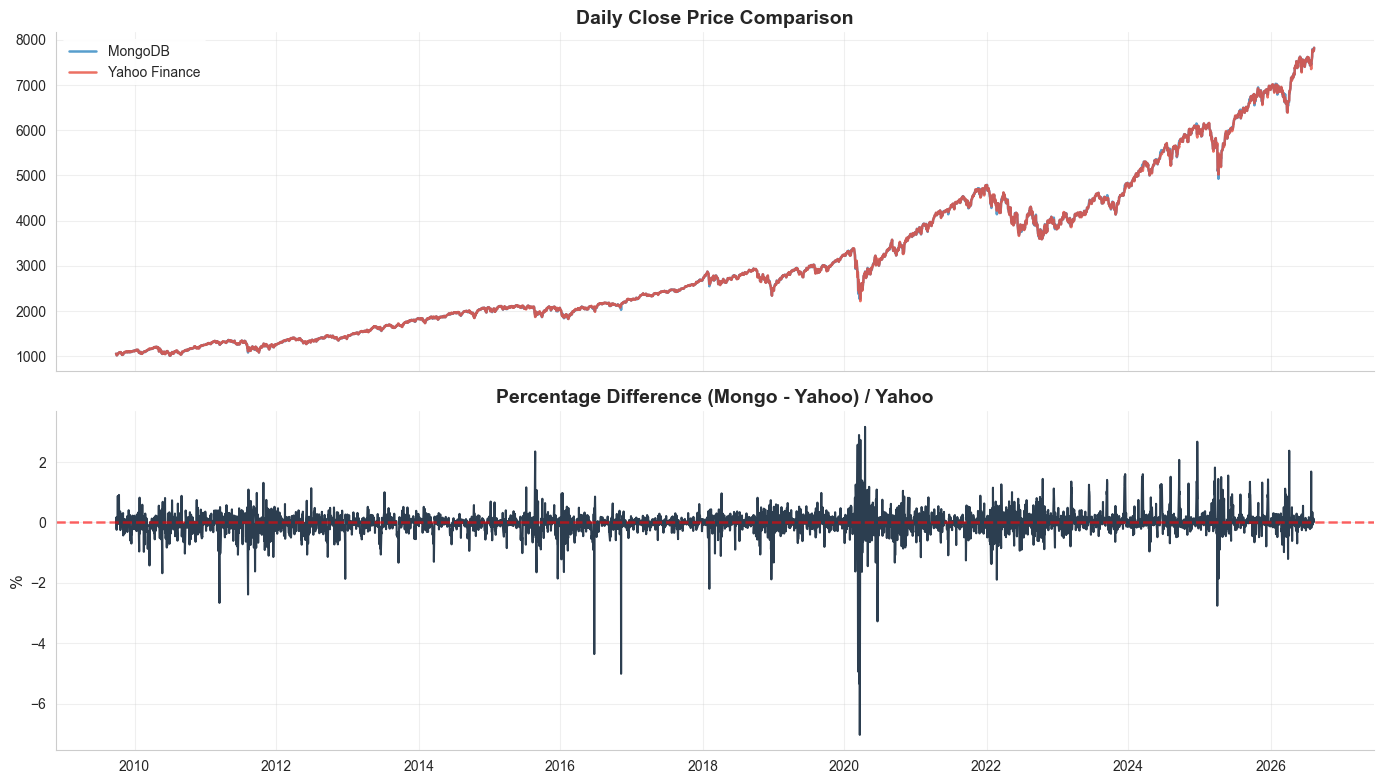

Mean difference: -0.0099%


In [11]:
df_daily = df_raw.resample('D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna()

es_yahoo = yf.download('ES=F', start=df_daily.index.min(), end=df_daily.index.max(), progress=False)
es_yahoo = es_yahoo[['Open', 'High', 'Low', 'Close', 'Volume']]
es_yahoo.columns = ['open', 'high', 'low', 'close', 'volume']

common_idx = df_daily.index.intersection(es_yahoo.index)
df_daily_aligned = df_daily.loc[common_idx]
es_yahoo_aligned = es_yahoo.loc[common_idx]

comparison = pd.DataFrame({
    'Mongo_close': df_daily_aligned['close'],
    'Yahoo_close': es_yahoo_aligned['close']
})
comparison['diff_pct'] = (comparison['Mongo_close'] - comparison['Yahoo_close']) / comparison['Yahoo_close'] * 100

print("Comparison with Yahoo Finance (daily closes):")
print(comparison.describe())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(comparison.index, comparison['Mongo_close'], label='MongoDB', color='#2E86C1', alpha=0.8)
ax1.plot(comparison.index, comparison['Yahoo_close'], label='Yahoo Finance', color='#E74C3C', alpha=0.8)
ax1.set_title('Daily Close Price Comparison', fontweight='bold')
ax1.legend(frameon=True, framealpha=0.9)
ax1.grid(True, alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax2.plot(comparison.index, comparison['diff_pct'], color='#2C3E50', linewidth=1.5)
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.6)
ax2.set_title('Percentage Difference (Mongo - Yahoo) / Yahoo', fontweight='bold')
ax2.set_ylabel('%')
ax2.grid(True, alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

mean_diff = comparison['diff_pct'].mean()
print(f"Mean difference: {mean_diff:.4f}%")

# 4. Resample to Multiple Timeframes

In [12]:
df_15min = df_raw.copy()
df_15min = df_15min[['open', 'high', 'low', 'close', 'volume']]

df_1h = df_raw.resample('h').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna()

df_4h = df_raw.resample('4h').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna()

df_1d = df_raw.resample('D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna()

print("Timeframes created:")
print(f"15min: {len(df_15min)}")
print(f"1H: {len(df_1h)}")
print(f"4H: {len(df_4h)}")
print(f"1D: {len(df_1d)}")

Timeframes created:
15min: 397203
1H: 101021
4H: 26970
1D: 5252


# 5. Helper Functions for AED (Enhanced Styling)

In [13]:
def compute_hurst(price_series, max_lag=100):
    lags = range(2, max_lag)
    tau = []
    for lag in lags:
        pp = np.subtract(price_series[lag:], price_series[:-lag])
        std = np.std(pp)
        if std == 0:
            continue
        mean = np.mean(pp)
        dev = pp - mean
        cumsum_dev = np.cumsum(dev)
        r = np.max(cumsum_dev) - np.min(cumsum_dev)
        tau.append(r / std)
    lags = np.array(lags[:len(tau)])
    tau = np.array(tau)
    if len(tau) < 3:
        return np.nan
    hurst = np.polyfit(np.log(lags), np.log(tau), 1)[0]
    return hurst

def compute_acf(series, nlags=40):
    return acf(series, nlags=nlags, fft=False)

def plot_distribution_detailed(df, ret_col='ret', name=''):
    ret = df[ret_col].dropna() * 100
    fig, ax = plt.subplots(figsize=(12, 5))
    n, bins, patches = ax.hist(ret, bins=100, density=True, alpha=0.6, color='#3498DB', edgecolor='black', linewidth=0.5)
    mu, std = norm.fit(ret)
    xmin, xmax = ret.min(), ret.max()
    x = np.linspace(xmin, xmax, 200)
    p = norm.pdf(x, mu, std)
    ax.plot(x, p, 'r-', linewidth=2.5, label=f'Normal fit (μ={mu:.2f}, σ={std:.2f})')
    
    ax.axvspan(xmin, mu - 3*std, alpha=0.15, color='red')
    ax.axvspan(mu + 3*std, xmax, alpha=0.15, color='red')
    ax.axvline(x=mu - 3*std, color='orange', linestyle='--', alpha=0.8, label='-3σ')
    ax.axvline(x=mu + 3*std, color='orange', linestyle='--', alpha=0.8, label='+3σ')
    
    ax.set_title(f'Your Returns (bars) vs Normal Distribution (line) - {name}', fontweight='bold')
    ax.set_xlabel('Return (%)')
    ax.set_ylabel('Density')
    ax.legend(frameon=True)
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.text(0.02, 0.95, f'σ = {std:.2f}%', transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
    
    fig.text(0.5, 0.01, 
             'Purpose: dimension real risk. Fat tails + negative skew = your stop and sizing must account for violent drops.', 
             ha='center', fontsize=10, style='italic')
    
    plt.tight_layout(rect=[0, 0.03, 1, 1])
    plt.show()
    return mu, std

def plot_volatility_detailed(df, ret_col='ret', window=20, name=''):
    ret = df[ret_col].dropna()
    vol_daily = ret.rolling(window).std() * 100
    vol_hist = ret.std() * 100
    vol_recent = ret.tail(window).std() * 100
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
    
    ax1.plot(vol_daily.index, vol_daily, color='#2C3E50', linewidth=1.5)
    ax1.axhline(y=vol_hist, color='#E74C3C', linestyle='--', alpha=0.7, label=f'Historical: {vol_hist:.2f}%')
    ax1.axhline(y=vol_recent, color='#2ECC71', linestyle='--', alpha=0.7, label=f'Recent: {vol_recent:.2f}%')
    ax1.set_title(f'Volatility Over Time - {name}', fontweight='bold')
    ax1.set_ylabel('Daily Volatility (%)')
    ax1.legend(frameon=True)
    ax1.grid(True, alpha=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    ret_pct = ret * 100
    colors = ['#2ECC71' if x > 0 else '#E74C3C' for x in ret_pct]
    ax2.bar(ret_pct.index, ret_pct, color=colors, alpha=0.6, width=0.8)
    ax2.axhline(y=0, color='black', linewidth=0.5)
    ax2.set_title('Daily Returns Over Time (green = up, red = down)', fontweight='bold')
    ax2.set_ylabel('Return (%)')
    ax2.grid(True, alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    max_ret = ret_pct.max()
    min_ret = ret_pct.min()
    ax2.text(0.02, 0.95, f'+{max_ret:.1f}%', transform=ax2.transAxes, fontsize=10, color='green', fontweight='bold')
    ax2.text(0.02, 0.05, f'{min_ret:.1f}%', transform=ax2.transAxes, fontsize=10, color='red', fontweight='bold')
    
    fig.text(0.5, 0.01, 
             'Purpose: adjust position sizing (less in volatile periods) and filter entries based on volatility regime.', 
             ha='center', fontsize=10, style='italic')
    
    plt.tight_layout(rect=[0, 0.03, 1, 1])
    plt.show()
    return vol_hist, vol_recent, vol_recent/vol_hist if vol_hist>0 else 0

def plot_acf_detailed(df, ret_col='ret', nlags=40, name=''):
    ret = df[ret_col].dropna()
    acf_vals = compute_acf(ret, nlags=nlags)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    colors = ['#2ECC71' if x > 0 else '#E74C3C' for x in acf_vals]
    ax1.bar(range(len(acf_vals)), acf_vals, color=colors, alpha=0.7, edgecolor='none')
    ax1.axhline(y=0, color='black', linewidth=0.5)
    
    ci = 1.96 / np.sqrt(len(ret))
    ax1.axhline(y=ci, color='gray', linestyle='--', alpha=0.6, label='Noise zone (95% CI)')
    ax1.axhline(y=-ci, color='gray', linestyle='--', alpha=0.6)
    ax1.fill_between(range(len(acf_vals)), -ci, ci, color='gray', alpha=0.1)
    
    ax1.set_title(f'Memory by Lag - {name}', fontweight='bold')
    ax1.set_xlabel('Lag')
    ax1.set_ylabel('Autocorrelation')
    ax1.legend(frameon=True, loc='upper right')
    ax1.grid(True, alpha=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    highlight_lags = [1, 2, 3, 5, 10, 20]
    for lag in highlight_lags:
        if lag < len(acf_vals):
            val = acf_vals[lag]
            y_offset = 0.02 if val >= 0 else -0.04
            ax1.text(lag, val + y_offset, f'{val:.3f}', 
                    ha='center', va='bottom' if val >= 0 else 'top', 
                    fontsize=8, fontweight='bold', color='black')
    
    ax1.text(len(acf_vals)-1, ci + 0.02, 'repeats (momentum)', 
             ha='right', va='bottom', fontsize=8, color='green', fontweight='bold')
    ax1.text(len(acf_vals)-1, -ci - 0.02, 'reverses', 
             ha='right', va='top', fontsize=8, color='red', fontweight='bold')
    ax1.text(len(acf_vals)-1, 0, 'noise zone = random', 
             ha='right', va='center', fontsize=8, color='gray', fontweight='bold')
    
    ret_shift = ret.shift(1).dropna()
    ret_today = ret.loc[ret_shift.index]
    
    ax2.scatter(ret_shift * 100, ret_today * 100, alpha=0.3, s=15, color='#3498DB')
    
    try:
        slope, intercept, r_value, p_value, std_err = linregress(ret_shift, ret_today)
        x_vals = np.linspace(ret_shift.min(), ret_shift.max(), 100)
        y_vals = slope * x_vals + intercept
        ax2.plot(x_vals * 100, y_vals * 100, 'r-', linewidth=2.5, label=f'Slope = {slope:.3f}')
    except:
        pass
    
    ax2.axhline(y=0, color='black', linewidth=0.5, alpha=0.5)
    ax2.axvline(x=0, color='black', linewidth=0.5, alpha=0.5)
    ax2.set_title("Today's Return vs Yesterday's Return", fontweight='bold')
    ax2.set_xlabel("Yesterday's Return (%)")
    ax2.set_ylabel("Today's Return (%)")
    ax2.legend(frameon=True)
    ax2.grid(True, alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    ax2.text(0.02, 0.95, 'followed direction', transform=ax2.transAxes, fontsize=9,
             verticalalignment='top', color='green', fontweight='bold')
    ax2.text(0.02, 0.05, 'reversed', transform=ax2.transAxes, fontsize=9,
             verticalalignment='bottom', color='red', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    return acf_vals

def plot_seasonality_detailed(df, ret_col='ret', name=''):
    ret = df[ret_col].dropna() * 100
    df_temp = df.loc[ret.index].copy()
    df_temp['ret_pct'] = ret
    
    if 'dayofweek' not in df_temp.columns:
        df_temp['dayofweek'] = df_temp.index.dayofweek
    day_means = df_temp.groupby('dayofweek')['ret_pct'].mean()
    day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    
    if 'month' not in df_temp.columns:
        df_temp['month'] = df_temp.index.month
    month_means = df_temp.groupby('month')['ret_pct'].mean()
    month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    
    hour_means = None
    if df.index.freq is not None and (df.index.freq.name in ['T', 'H'] or df.index.freq == 'h'):
        df_temp['hour'] = df_temp.index.hour
        hour_means = df_temp.groupby('hour')['ret_pct'].mean()
    
    fig, axes = plt.subplots(1, 3 if hour_means is not None else 2, figsize=(15 if hour_means is not None else 10, 4))
    if hour_means is None:
        axes = [axes[0], axes[1]]
    
    ax = axes[0]
    days_to_plot = [d for d in range(len(day_means)) if d < 5]
    colors_day = ['#2ECC71' if day_means[i] > 0 else '#E74C3C' for i in days_to_plot]
    ax.bar([day_names[i] for i in days_to_plot], [day_means[i] for i in days_to_plot], 
           color=colors_day, alpha=0.7, edgecolor='none')
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_title(f'Average Return by Day (Mon-Fri) - {name}', fontweight='bold')
    ax.set_ylabel('Mean Return (%)')
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax = axes[1]
    colors_month = ['#2ECC71' if x > 0 else '#E74C3C' for x in month_means.values]
    ax.bar(month_names, month_means.values, color=colors_month, alpha=0.7, edgecolor='none')
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_title(f'Average Return by Month - {name}', fontweight='bold')
    ax.set_ylabel('Mean Return (%)')
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    if hour_means is not None:
        ax = axes[2]
        hours_to_plot = [h for h in hour_means.index if 6 <= h <= 22]
        colors_hour = ['#2ECC71' if hour_means[h] > 0 else '#E74C3C' for h in hours_to_plot]
        ax.bar(hours_to_plot, [hour_means[h] for h in hours_to_plot], 
               color=colors_hour, alpha=0.7, edgecolor='none')
        ax.axhline(y=0, color='black', linewidth=0.5)
        ax.set_title(f'Average Return by Hour (6:00-22:00) - {name}', fontweight='bold')
        ax.set_xlabel('Hour of Day')
        ax.set_ylabel('Mean Return (%)')
        ax.grid(True, alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    return day_means, month_means, hour_means

def plot_extreme_events_detailed(df, ret_col='ret', top_n=12, name=''):
    ret = df[ret_col].dropna() * 100
    top_up = ret.nlargest(top_n)
    top_down = ret.nsmallest(top_n)
    extremes = pd.concat([top_up, top_down]).sort_values()
    
    fig, ax = plt.subplots(figsize=(10, 7))
    colors = ['#2ECC71' if x > 0 else '#E74C3C' for x in extremes.values]
    bars = ax.barh(range(len(extremes)), extremes.values, color=colors, alpha=0.8, edgecolor='none', height=0.7)
    ax.axvline(x=0, color='black', linewidth=0.5)
    ax.set_title(f'Top {top_n} Most Extreme Days - {name}', fontweight='bold')
    ax.set_xlabel('Return (%)')
    ax.set_ylabel('')
    ax.grid(True, axis='x', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_yticks(range(len(extremes)))
    ax.set_yticklabels([d.strftime('%Y-%m-%d') for d in extremes.index])
    
    for i, (date, val) in enumerate(extremes.items()):
        ax.text(val + (0.8 if val > 0 else -0.8), i, f'{val:.1f}%', 
                verticalalignment='center', fontsize=8, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    return top_up, top_down

def compute_acf(series, nlags=40):
    return acf(series, nlags=nlags, fft=False)

def plot_distribution_detailed(df, ret_col='ret', name=''):
    ret = df[ret_col].dropna() * 100
    fig, ax = plt.subplots(figsize=(12, 5))
    n, bins, patches = ax.hist(ret, bins=100, density=True, alpha=0.6, color='#3498DB', edgecolor='black', linewidth=0.5)
    mu, std = norm.fit(ret)
    xmin, xmax = ret.min(), ret.max()
    x = np.linspace(xmin, xmax, 200)
    p = norm.pdf(x, mu, std)
    ax.plot(x, p, 'r-', linewidth=2.5, label=f'Normal fit (μ={mu:.2f}, σ={std:.2f})')
    
    ax.axvspan(xmin, mu - 3*std, alpha=0.15, color='red')
    ax.axvspan(mu + 3*std, xmax, alpha=0.15, color='red')
    ax.axvline(x=mu - 3*std, color='orange', linestyle='--', alpha=0.8, label='-3σ')
    ax.axvline(x=mu + 3*std, color='orange', linestyle='--', alpha=0.8, label='+3σ')
    
    ax.set_title(f'Your Returns (bars) vs Normal Distribution (line) - {name}', fontweight='bold')
    ax.set_xlabel('Return (%)')
    ax.set_ylabel('Density')
    ax.legend(frameon=True)
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.text(0.02, 0.95, f'σ = {std:.2f}%', transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
    
    # Purpose explanation
    fig.text(0.5, 0.01, 
             'Purpose: dimension real risk. Fat tails + negative skew = your stop and sizing must account for violent drops.', 
             ha='center', fontsize=10, style='italic')
    
    plt.tight_layout(rect=[0, 0.03, 1, 1])
    plt.show()
    return mu, std

def plot_volatility_detailed(df, ret_col='ret', window=20, name=''):
    ret = df[ret_col].dropna()
    vol_daily = ret.rolling(window).std() * 100
    vol_hist = ret.std() * 100
    vol_recent = ret.tail(window).std() * 100
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
    
    ax1.plot(vol_daily.index, vol_daily, color='#2C3E50', linewidth=1.5)
    ax1.axhline(y=vol_hist, color='#E74C3C', linestyle='--', alpha=0.7, label=f'Historical: {vol_hist:.2f}%')
    ax1.axhline(y=vol_recent, color='#2ECC71', linestyle='--', alpha=0.7, label=f'Recent: {vol_recent:.2f}%')
    ax1.set_title(f'Volatility Over Time - {name}', fontweight='bold')
    ax1.set_ylabel('Daily Volatility (%)')
    ax1.legend(frameon=True)
    ax1.grid(True, alpha=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    ret_pct = ret * 100
    colors = ['#2ECC71' if x > 0 else '#E74C3C' for x in ret_pct]
    ax2.bar(ret_pct.index, ret_pct, color=colors, alpha=0.6, width=0.8)
    ax2.axhline(y=0, color='black', linewidth=0.5)
    ax2.set_title('Daily Returns Over Time (green = up, red = down)', fontweight='bold')
    ax2.set_ylabel('Return (%)')
    ax2.grid(True, alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    max_ret = ret_pct.max()
    min_ret = ret_pct.min()
    ax2.text(0.02, 0.95, f'+{max_ret:.1f}%', transform=ax2.transAxes, fontsize=10, color='green', fontweight='bold')
    ax2.text(0.02, 0.05, f'{min_ret:.1f}%', transform=ax2.transAxes, fontsize=10, color='red', fontweight='bold')
    
    # Purpose explanation
    fig.text(0.5, 0.01, 
             'Purpose: adjust position sizing (less in volatile periods) and filter entries based on volatility regime.', 
             ha='center', fontsize=10, style='italic')
    
    plt.tight_layout(rect=[0, 0.03, 1, 1])
    plt.show()
    return vol_hist, vol_recent, vol_recent/vol_hist if vol_hist>0 else 0

def plot_acf_detailed(df, ret_col='ret', nlags=40, name=''):
    ret = df[ret_col].dropna()
    acf_vals = compute_acf(ret, nlags=nlags)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # ============================================================
    # LEFT PLOT: ACF bar chart
    # ============================================================
    colors = ['#2ECC71' if x > 0 else '#E74C3C' for x in acf_vals]
    ax1.bar(range(len(acf_vals)), acf_vals, color=colors, alpha=0.7, edgecolor='none')
    ax1.axhline(y=0, color='black', linewidth=0.5)
    
    # Noise zone (95% CI)
    ci = 1.96 / np.sqrt(len(ret))
    ax1.axhline(y=ci, color='gray', linestyle='--', alpha=0.6, label='Noise zone (95% CI)')
    ax1.axhline(y=-ci, color='gray', linestyle='--', alpha=0.6)
    ax1.fill_between(range(len(acf_vals)), -ci, ci, color='gray', alpha=0.1)
    
    ax1.set_title(f'Memory by Lag - {name}', fontweight='bold')
    ax1.set_xlabel('Lag')
    ax1.set_ylabel('Autocorrelation')
    ax1.legend(frameon=True, loc='upper right')
    ax1.grid(True, alpha=0.3)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    
    # Add value labels for specific lags (1, 2, 3, 5, 10, 20)
    highlight_lags = [1, 2, 3, 5, 10, 20]
    for lag in highlight_lags:
        if lag < len(acf_vals):
            val = acf_vals[lag]
            y_offset = 0.02 if val >= 0 else -0.04
            ax1.text(lag, val + y_offset, f'{val:.3f}', 
                    ha='center', va='bottom' if val >= 0 else 'top', 
                    fontsize=8, fontweight='bold', color='black')
    
    # Add zone annotations
    ax1.text(len(acf_vals)-1, ci + 0.02, 'se repite (momentum)', 
             ha='right', va='bottom', fontsize=8, color='green', fontweight='bold')
    ax1.text(len(acf_vals)-1, -ci - 0.02, 'se invierte (reversión)', 
             ha='right', va='top', fontsize=8, color='red', fontweight='bold')
    ax1.text(len(acf_vals)-1, 0, 'zona de ruido = casualidad', 
             ha='right', va='center', fontsize=8, color='gray', fontweight='bold')
    
    # ============================================================
    # RIGHT PLOT: Scatter - Today's Return vs Yesterday's Return
    # ============================================================
    ret_shift = ret.shift(1).dropna()
    ret_today = ret.loc[ret_shift.index]
    
    ax2.scatter(ret_shift * 100, ret_today * 100, alpha=0.3, s=15, color='#3498DB')
    
    # Regression line
    try:
        slope, intercept, r_value, p_value, std_err = linregress(ret_shift, ret_today)
        x_vals = np.linspace(ret_shift.min(), ret_shift.max(), 100)
        y_vals = slope * x_vals + intercept
        ax2.plot(x_vals * 100, y_vals * 100, 'r-', linewidth=2.5, label=f'Slope = {slope:.3f}')
    except:
        pass
    
    ax2.axhline(y=0, color='black', linewidth=0.5, alpha=0.5)
    ax2.axvline(x=0, color='black', linewidth=0.5, alpha=0.5)
    ax2.set_title("Today's Return vs Yesterday's Return", fontweight='bold')
    ax2.set_xlabel("Yesterday's Return (%)")
    ax2.set_ylabel("Today's Return (%)")
    ax2.legend(frameon=True)
    ax2.grid(True, alpha=0.3)
    ax2.spines['top'].set_visible(False)
    ax2.spines['right'].set_visible(False)
    
    # Annotations
    ax2.text(0.02, 0.95, 'followed direction', transform=ax2.transAxes, fontsize=9,
             verticalalignment='top', color='green', fontweight='bold')
    ax2.text(0.02, 0.05, 'reversed', transform=ax2.transAxes, fontsize=9,
             verticalalignment='bottom', color='red', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    return acf_vals

def plot_seasonality_detailed(df, ret_col='ret', name=''):
    ret = df[ret_col].dropna() * 100
    df_temp = df.loc[ret.index].copy()
    df_temp['ret_pct'] = ret
    
    if 'dayofweek' not in df_temp.columns:
        df_temp['dayofweek'] = df_temp.index.dayofweek
    day_means = df_temp.groupby('dayofweek')['ret_pct'].mean()
    day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    
    if 'month' not in df_temp.columns:
        df_temp['month'] = df_temp.index.month
    month_means = df_temp.groupby('month')['ret_pct'].mean()
    month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    
    hour_means = None
    if df.index.freq is not None and (df.index.freq.name in ['T', 'H'] or df.index.freq == 'h'):
        df_temp['hour'] = df_temp.index.hour
        hour_means = df_temp.groupby('hour')['ret_pct'].mean()
    
    fig, axes = plt.subplots(1, 3 if hour_means is not None else 2, figsize=(15 if hour_means is not None else 10, 4))
    if hour_means is None:
        axes = [axes[0], axes[1]]
    
    ax = axes[0]
    days_to_plot = [d for d in range(len(day_means)) if d < 5]
    colors_day = ['#2ECC71' if day_means[i] > 0 else '#E74C3C' for i in days_to_plot]
    ax.bar([day_names[i] for i in days_to_plot], [day_means[i] for i in days_to_plot], 
           color=colors_day, alpha=0.7, edgecolor='none')
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_title(f'Average Return by Day (Mon-Fri) - {name}', fontweight='bold')
    ax.set_ylabel('Mean Return (%)')
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    ax = axes[1]
    colors_month = ['#2ECC71' if x > 0 else '#E74C3C' for x in month_means.values]
    ax.bar(month_names, month_means.values, color=colors_month, alpha=0.7, edgecolor='none')
    ax.axhline(y=0, color='black', linewidth=0.5)
    ax.set_title(f'Average Return by Month - {name}', fontweight='bold')
    ax.set_ylabel('Mean Return (%)')
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    if hour_means is not None:
        ax = axes[2]
        hours_to_plot = [h for h in hour_means.index if 6 <= h <= 22]
        colors_hour = ['#2ECC71' if hour_means[h] > 0 else '#E74C3C' for h in hours_to_plot]
        ax.bar(hours_to_plot, [hour_means[h] for h in hours_to_plot], 
               color=colors_hour, alpha=0.7, edgecolor='none')
        ax.axhline(y=0, color='black', linewidth=0.5)
        ax.set_title(f'Average Return by Hour (6:00-22:00) - {name}', fontweight='bold')
        ax.set_xlabel('Hour of Day')
        ax.set_ylabel('Mean Return (%)')
        ax.grid(True, alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    return day_means, month_means, hour_means

def plot_extreme_events_detailed(df, ret_col='ret', top_n=12, name=''):
    ret = df[ret_col].dropna() * 100
    top_up = ret.nlargest(top_n)
    top_down = ret.nsmallest(top_n)
    extremes = pd.concat([top_up, top_down]).sort_values()
    
    fig, ax = plt.subplots(figsize=(10, 7))
    colors = ['#2ECC71' if x > 0 else '#E74C3C' for x in extremes.values]
    bars = ax.barh(range(len(extremes)), extremes.values, color=colors, alpha=0.8, edgecolor='none', height=0.7)
    ax.axvline(x=0, color='black', linewidth=0.5)
    ax.set_title(f'Top {top_n} Most Extreme Days - {name}', fontweight='bold')
    ax.set_xlabel('Return (%)')
    ax.set_ylabel('')
    ax.grid(True, axis='x', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_yticks(range(len(extremes)))
    ax.set_yticklabels([d.strftime('%Y-%m-%d') for d in extremes.index])
    
    for i, (date, val) in enumerate(extremes.items()):
        ax.text(val + (0.8 if val > 0 else -0.8), i, f'{val:.1f}%', 
                verticalalignment='center', fontsize=8, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    return top_up, top_down

# 6. Detailed AED Function (with Multi-Factor Classification)

In [14]:
def analyze_timeframe_detailed(df, name):
    print(f"\n{'='*70}")
    print(f"COMPLETE ANALYSIS: {name}")
    print(f"{'='*70}")
    print(f"Bars: {len(df)}")
    print(f"Period: {df.index.min()} → {df.index.max()}")
    
    df = df.copy()
    df['ret'] = df['close'].pct_change()
    df['log_ret'] = np.log(df['close'] / df['close'].shift(1))
    ret = df['ret'].dropna()
    
    print("\n" + "="*70)
    print("SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)")
    print("="*70)
    
    hurst = compute_hurst(df['close'].values, max_lag=min(100, len(df)//2))
    if not np.isnan(hurst):
        if hurst < 0.45:
            cp = "MEAN REVERSION"
        elif hurst > 0.55:
            cp = "TRENDING"
        else:
            cp = "RANDOM WALK"
        print(f"{cp}")
        print(f"Hurst {hurst:.2f}")
    else:
        print("Hurst not available")
    
    precio_inicial = df['close'].iloc[0]
    precio_final = df['close'].iloc[-1]
    años = (df.index.max() - df.index.min()).days / 365.25
    cagr = ((precio_final / precio_inicial) ** (1 / años) - 1) * 100 if años > 0 else 0
    mean_ret_annual = cagr
    
    if mean_ret_annual > 2:
        deriva = "BULLISH"
    elif mean_ret_annual < -2:
        deriva = "BEARISH"
    else:
        deriva = "NEUTRAL"
    print(f"{deriva}")
    print(f"~{mean_ret_annual:.1f}%/year (mean return)")
    
    print("\n" + "="*70)
    print("DISTRIBUTION")
    print("TAILS?")
    print("="*70)
    
    ret_pct = ret * 100
    mean_ret = ret_pct.mean()
    
    # Volatility using DAILY LOG RETURNS to match online tool
    df_daily = df.resample('D').agg({
        'close': 'last'
    }).dropna()
    df_daily['log_ret'] = np.log(df_daily['close'] / df_daily['close'].shift(1))
    daily_log_ret = df_daily['log_ret'].dropna()
    vol_ann = daily_log_ret.std() * np.sqrt(252) * 100 if len(daily_log_ret) > 0 else np.nan
    
    skew = ret_pct.skew()
    kurt = ret_pct.kurtosis()
    jb_stat, jb_p = jarque_bera(ret_pct)
    normal = "NOT normal" if jb_p < 0.05 else "Normal"
    three_sigma = 3 * ret.std() * 100
    extreme_days = ret_pct[np.abs(ret_pct) > three_sigma]
    pct_extreme = len(extreme_days) / len(ret_pct) * 100
    
    if skew > 0.1:
        skew_label = "right tail"
    elif skew < -0.1:
        skew_label = "left tail"
    else:
        skew_label = "symmetric"
    
    if kurt > 3:
        kurt_label = "fat tails"
    elif kurt < -1:
        kurt_label = "thin tails"
    else:
        kurt_label = "normal"
    
    print(f"Mean return: {mean_ret:.2f}%")
    print(f"Annualized volatility: {vol_ann:.1f}%")
    print(f"Skewness: {skew:.2f} ({skew_label})")
    print(f"Excess Kurtosis: {kurt:.2f} ({kurt_label})")
    print(f"Normality: {normal}")
    print(f"Extreme days (>3σ): {len(extreme_days)} ({pct_extreme:.1f}%)")
    
    mu_fit, std_fit = plot_distribution_detailed(df, 'ret', name)
    
    print("\n" + "="*70)
    print("VOLATILITY")
    print("REGIMES?")
    print("="*70)
    
    vol_hist = ret.std() * 100
    vol_recent = ret.tail(20).std() * 100
    ratio = vol_recent / vol_hist if vol_hist > 0 else 0
    vol_sq = ret**2
    arch_lag1 = vol_sq.autocorr(lag=1) if len(vol_sq) > 1 else np.nan
    clustering = "low" if arch_lag1 < 0.2 else "moderate" if arch_lag1 < 0.4 else "strong"
    
    print(f"Recent vs Mean vol: {ratio:.2f}x")
    print(f"Recent volatility (daily): {vol_recent:.2f}%")
    print(f"Historical volatility (daily): {vol_hist:.2f}%")
    print(f"Comes in waves? {clustering}")
    
    vol_hist_val, vol_recent_val, ratio_val = plot_volatility_detailed(df, 'ret', 20, name)
    
    print("\n" + "="*70)
    print("AUTOCORRELATION · MEMORY")
    print("PERSISTENCE?")
    print("="*70)
    
    acf_vals = compute_acf(ret, nlags=40)
    for lag in [1, 5, 20]:
        if lag < len(acf_vals):
            val = acf_vals[lag]
            interpret = "reverts" if val < 0 else "persists" if val > 0.05 else "~0"
            print(f"Lag {lag} · vs {'yesterday' if lag==1 else f'{lag} days ago'}: {val:.2f} {interpret}")
    
    acf_vals = plot_acf_detailed(df, 'ret', 40, name)
    
    print("\n" + "="*70)
    print("PATTERNS")
    print("SEASONALITY?")
    print("="*70)
    
    day_means, month_means, hour_means = plot_seasonality_detailed(df, 'ret', name)
    
    day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri']
    print("\nAverage return by day of week (Mon-Fri, %):")
    for i in range(5):
        if i in day_means.index:
            print(f"{day_names[i]}: {day_means[i]:.2f}%")
    
    month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    print("\nAverage return by month (%):")
    for i, val in month_means.items():
        print(f"{month_names[i-1]}: {val:.2f}%")
    
    if hour_means is not None:
        print("\nAverage return by hour (6:00-22:00, %):")
        for h in range(6, 23):
            if h in hour_means.index:
                print(f"{h:02d}:00: {hour_means[h]:.2f}%")
    
    print("\n" + "="*70)
    print("EXTREME EVENTS")
    print("REACTION?")
    print("="*70)
    
    top_up, top_down = plot_extreme_events_detailed(df, 'ret', 12, name)
    
    print(f"Biggest up: +{top_up.max():.1f}%")
    print(f"Biggest down: {top_down.min():.1f}%")
    print(f"Shock days (>3σ): {len(extreme_days)} of {len(ret):,} returns · {pct_extreme:.2f}%")
    
    print("\nTop 12 up days:")
    for date, val in top_up.items():
        print(f"+{val:.1f}% - {date.strftime('%Y-%m-%d')}")
    
    print("\nTop 12 down days:")
    for date, val in top_down.items():
        print(f"{val:.1f}% - {date.strftime('%Y-%m-%d')}")
    
    print("\n" + "="*70)
    print("FROM BEHAVIOR TO SYSTEM")
    print("="*70)
    
    score_mr = 0
    score_trend = 0
    
    if not np.isnan(hurst):
        if hurst < 0.45:
            score_mr += 40
        elif hurst > 0.55:
            score_trend += 40
        else:
            score_mr += 20
            score_trend += 20
    
    acf1 = acf_vals[1] if len(acf_vals) > 1 else 0
    if acf1 < -0.05:
        score_mr += 30
    elif acf1 > 0.05:
        score_trend += 30
    else:
        score_mr += 15
        score_trend += 15
    
    arch = arch_lag1 if not np.isnan(arch_lag1) else 0
    if arch > 0.3:
        score_trend += 15
    elif arch < 0.15:
        score_mr += 15
    else:
        score_mr += 7.5
        score_trend += 7.5
    
    if skew < -0.5 and kurt > 3:
        score_mr += 15
    elif skew > 0.5 and kurt > 3:
        score_trend += 15
    else:
        score_mr += 7.5
        score_trend += 7.5
    
    total = score_mr + score_trend
    if total > 0:
        mr_pct = (score_mr / total) * 100
        trend_pct = (score_trend / total) * 100
    else:
        mr_pct = 50
        trend_pct = 50
    
    print(f"Mean reversion: {mr_pct:.0f}%")
    print(f"Trending: {trend_pct:.0f}%")
    
    if mr_pct > trend_pct + 10:
        rec = "MEAN REVERSION"
        rec_explore = "fade / reversal"
    elif trend_pct > mr_pct + 10:
        rec = "TRENDING"
        rec_explore = "momentum / breakout"
    else:
        rec = f"MIXED (MR: {mr_pct:.0f}%, Trend: {trend_pct:.0f}%)"
        rec_explore = "a combination of both"
    
    print(f"\nThis asset is more likely {rec} → explore {rec_explore}.")
    
    print("\n" + "-"*50)
    print("If the asset shows...\tExplore...\tIn this asset")
    print("-"*50)
    
    acf_label = "positive" if acf1 > 0.05 else "negative" if acf1 < -0.05 else "neutral"
    acf_pct = f"{mr_pct:.0f}%" if acf1 < -0.05 else f"{trend_pct:.0f}%" if acf1 > 0.05 else "~0%"
    print(f"Autocorrelation {acf_label}\t→ {'trend / momentum' if acf1 > 0 else 'mean reversion' if acf1 < 0 else 'random'}\t{acf_pct}")
    
    vol_reg = "high" if arch > 0.3 else "low"
    print(f"Volatility regimes\t→ volatility expansion\t{vol_reg}")
    
    day_std = day_means.std() if len(day_means) > 0 else 0
    month_std = month_means.std() if len(month_means) > 0 else 0
    seasonal = "high" if (day_std > 0.1 or month_std > 0.1) else "low"
    print(f"Seasonal patterns\t→ seasonal systems\t{seasonal}")
    
    event = "high" if pct_extreme > 2 else "low" if pct_extreme < 0.5 else "medium"
    print(f"Response to events\t→ event-driven\t{event}")
    
    print("\n" + "="*70)
    print("GLOSSARY")
    print("WHAT EACH NUMBER MEANS")
    print("="*70)
    
    print(f"""
Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ {mean_ret:.2f}%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ {vol_ann:.1f}%

Skewness
Which side the surprises lean toward. {'Negative' if skew < 0 else 'Positive'} means {'down' if skew < 0 else 'up'} moves are more violent than {'up' if skew < 0 else 'down'} moves.
→ {skew:.2f} ({skew_label})

Excess Kurtosis
How frequent extreme events are. {'High' if kurt > 3 else 'Low'} = {'more' if kurt > 3 else 'fewer'} shocks than a normal distribution would predict.
→ {kurt:.2f} ({kurt_label})

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ {normal}

Autocorrelation
Whether today's return resembles yesterday's. {'Positive' if acf1 > 0 else 'Negative'} means {'persistence (momentum)' if acf1 > 0 else 'reversal (mean reversion)'}.
→ Lag 1: {acf1:.3f}

Hurst Exponent
Measures price memory. {'>0.5' if hurst > 0.5 else '<0.5' if hurst < 0.5 else '~0.5'} = {'trending' if hurst > 0.5 else 'reverting' if hurst < 0.5 else 'random walk (no memory)'}.
→ {hurst:.3f}

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ {clustering}

Seasonality
Whether certain days, months, or hours consistently yield different returns (e.g., the "Monday effect").
→ {'Yes' if seasonal == 'high' else 'Low'}

Extreme Events
The largest moves in history. Measure the surprise risk your system must withstand.
→ {len(extreme_days)} days >3σ ({pct_extreme:.1f}%)
""")
    
    print(f"\n{'='*70}\n")
    
    return {
        'name': name,
        'mean_ret': mean_ret,
        'vol_ann': vol_ann,
        'skew': skew,
        'kurt': kurt,
        'normal': normal,
        'pct_extreme': pct_extreme,
        'hurst': hurst,
        'mr_pct': mr_pct,
        'trend_pct': trend_pct,
        'acf1': acf1,
        'arch': arch_lag1,
        'seasonal': seasonal,
        'event': event
    }

# 7. Run Detailed AED on Each Timeframe


COMPLETE ANALYSIS: 15min
Bars: 397203
Period: 2009-09-27 18:00:00 → 2026-08-14 16:45:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.50
BULLISH
~12.7%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: 0.00%
Annualized volatility: 15.4%
Skewness: -0.22 (left tail)
Excess Kurtosis: 83.69 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 6831 (1.7%)


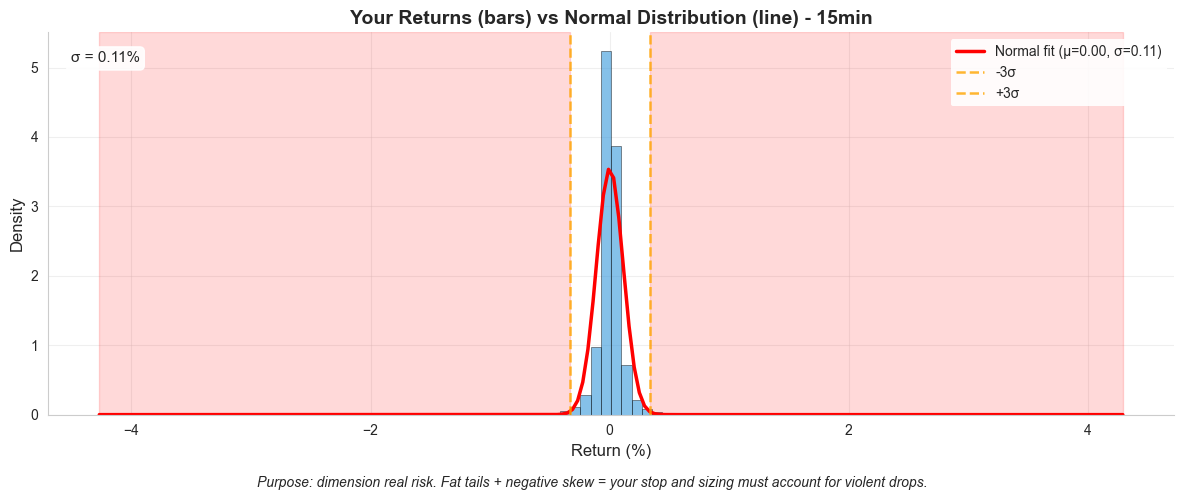


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.31x
Recent volatility (daily): 0.03%
Historical volatility (daily): 0.11%
Comes in waves? low


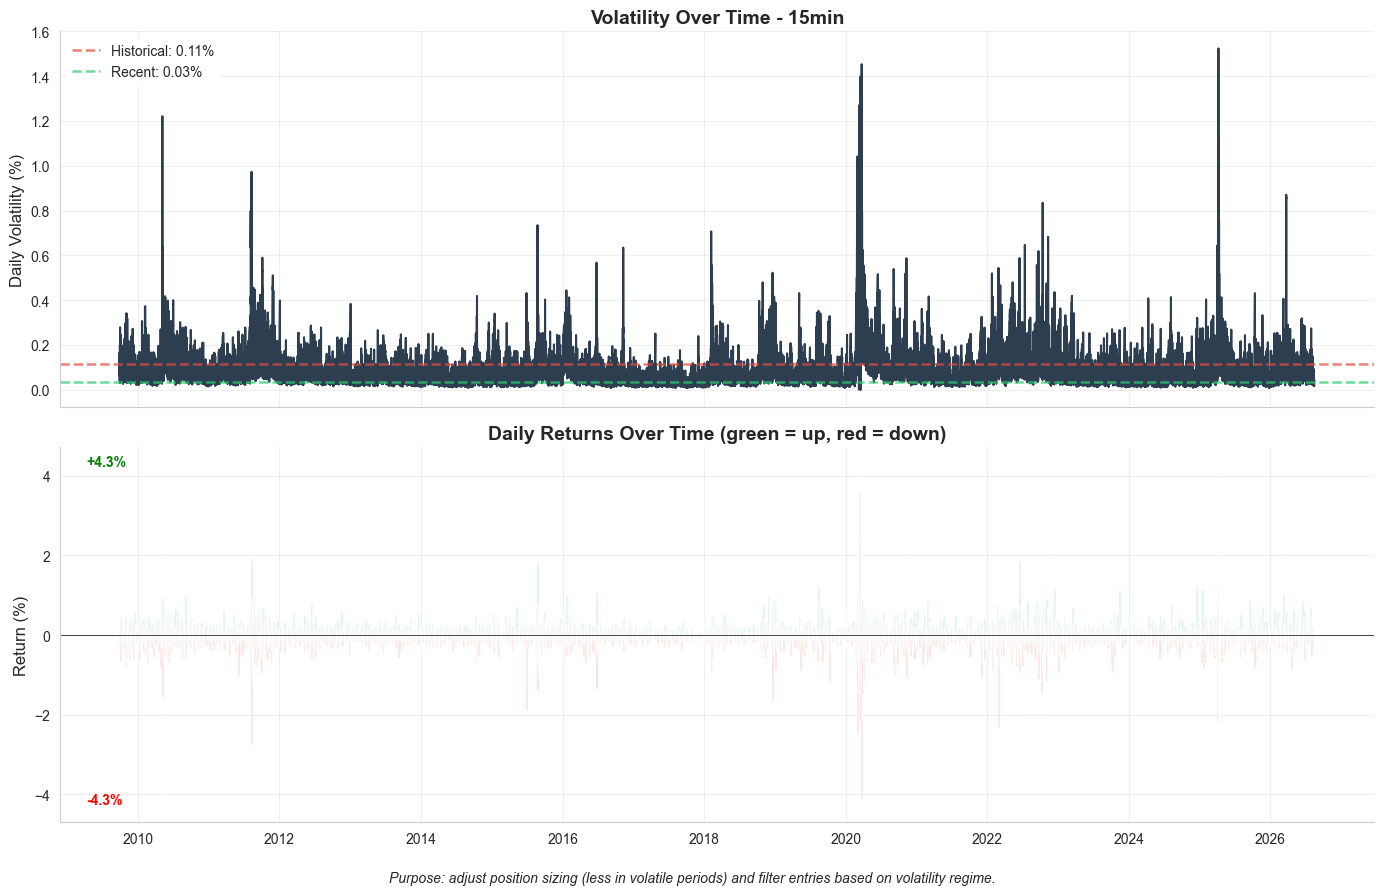


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: -0.01 reverts


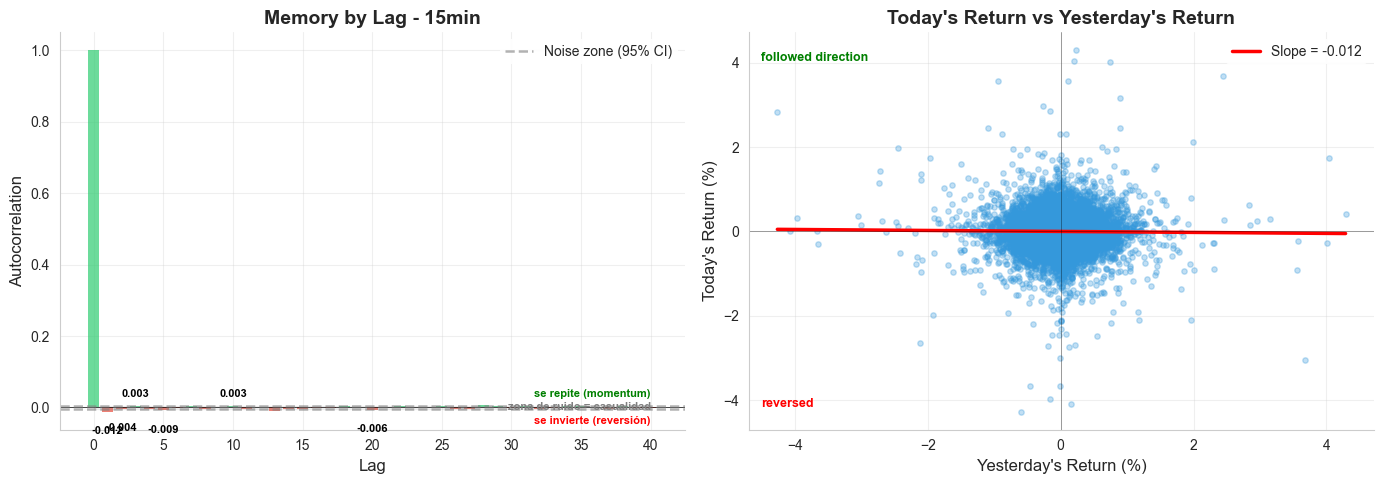


PATTERNS
SEASONALITY?


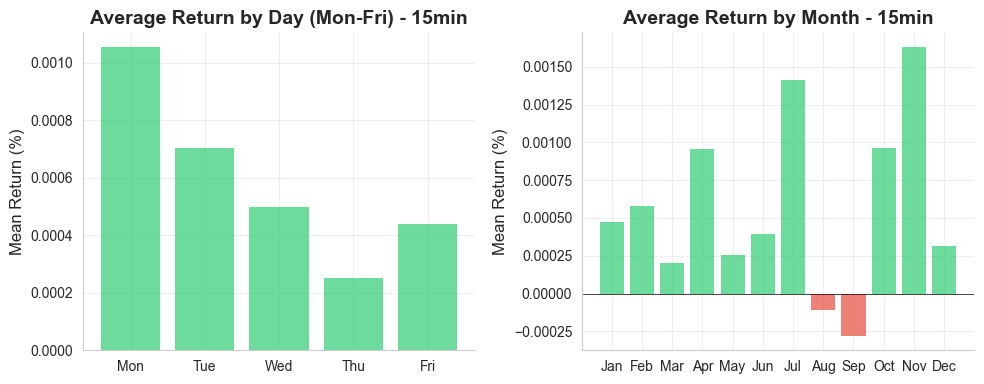


Average return by day of week (Mon-Fri, %):
Mon: 0.00%
Tue: 0.00%
Wed: 0.00%
Thu: 0.00%
Fri: 0.00%

Average return by month (%):
Jan: 0.00%
Feb: 0.00%
Mar: 0.00%
Apr: 0.00%
May: 0.00%
Jun: 0.00%
Jul: 0.00%
Aug: -0.00%
Sep: -0.00%
Oct: 0.00%
Nov: 0.00%
Dec: 0.00%

EXTREME EVENTS
REACTION?


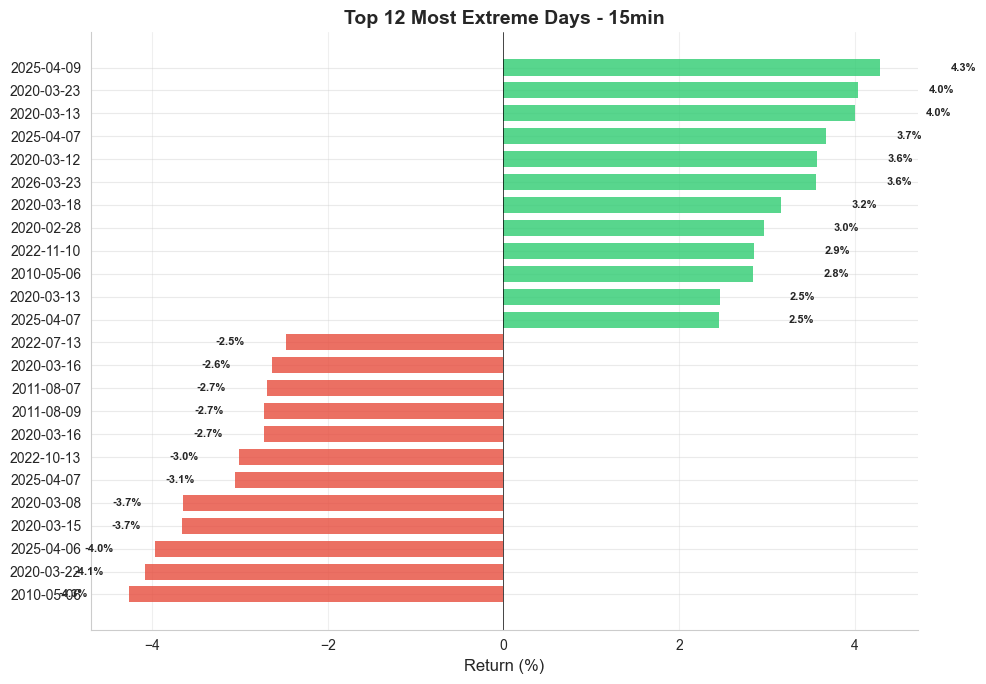

Biggest up: +4.3%
Biggest down: -4.3%
Shock days (>3σ): 6831 of 397,202 returns · 1.72%

Top 12 up days:
+4.3% - 2025-04-09
+4.0% - 2020-03-23
+4.0% - 2020-03-13
+3.7% - 2025-04-07
+3.6% - 2020-03-12
+3.6% - 2026-03-23
+3.2% - 2020-03-18
+3.0% - 2020-02-28
+2.9% - 2022-11-10
+2.8% - 2010-05-06
+2.5% - 2020-03-13
+2.5% - 2025-04-07

Top 12 down days:
-4.3% - 2010-05-06
-4.1% - 2020-03-22
-4.0% - 2025-04-06
-3.7% - 2020-03-15
-3.7% - 2020-03-08
-3.1% - 2025-04-07
-3.0% - 2022-10-13
-2.7% - 2020-03-16
-2.7% - 2011-08-09
-2.7% - 2011-08-07
-2.6% - 2020-03-16
-2.5% - 2022-07-13

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal sys

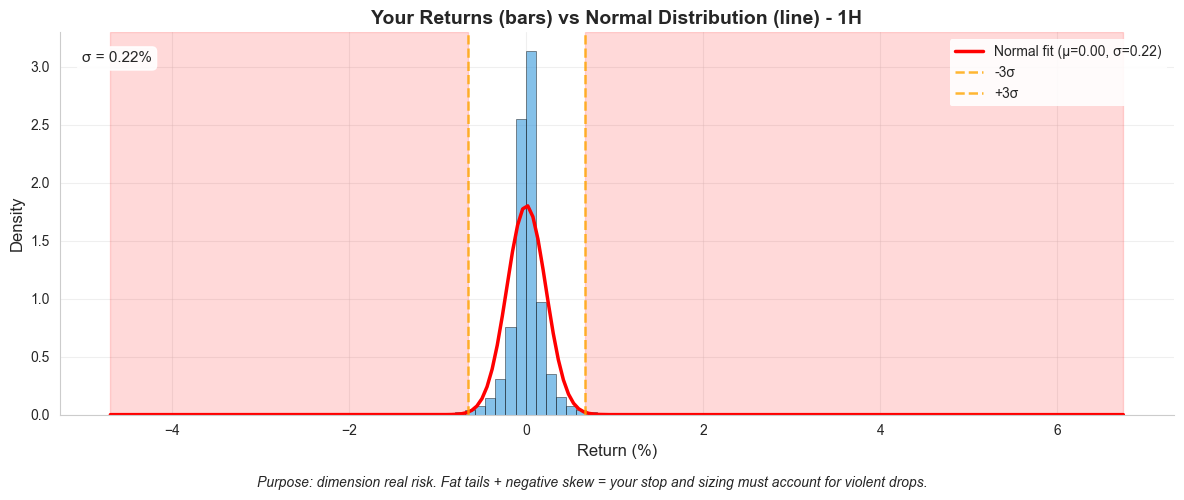


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.26x
Recent volatility (daily): 0.06%
Historical volatility (daily): 0.22%
Comes in waves? low


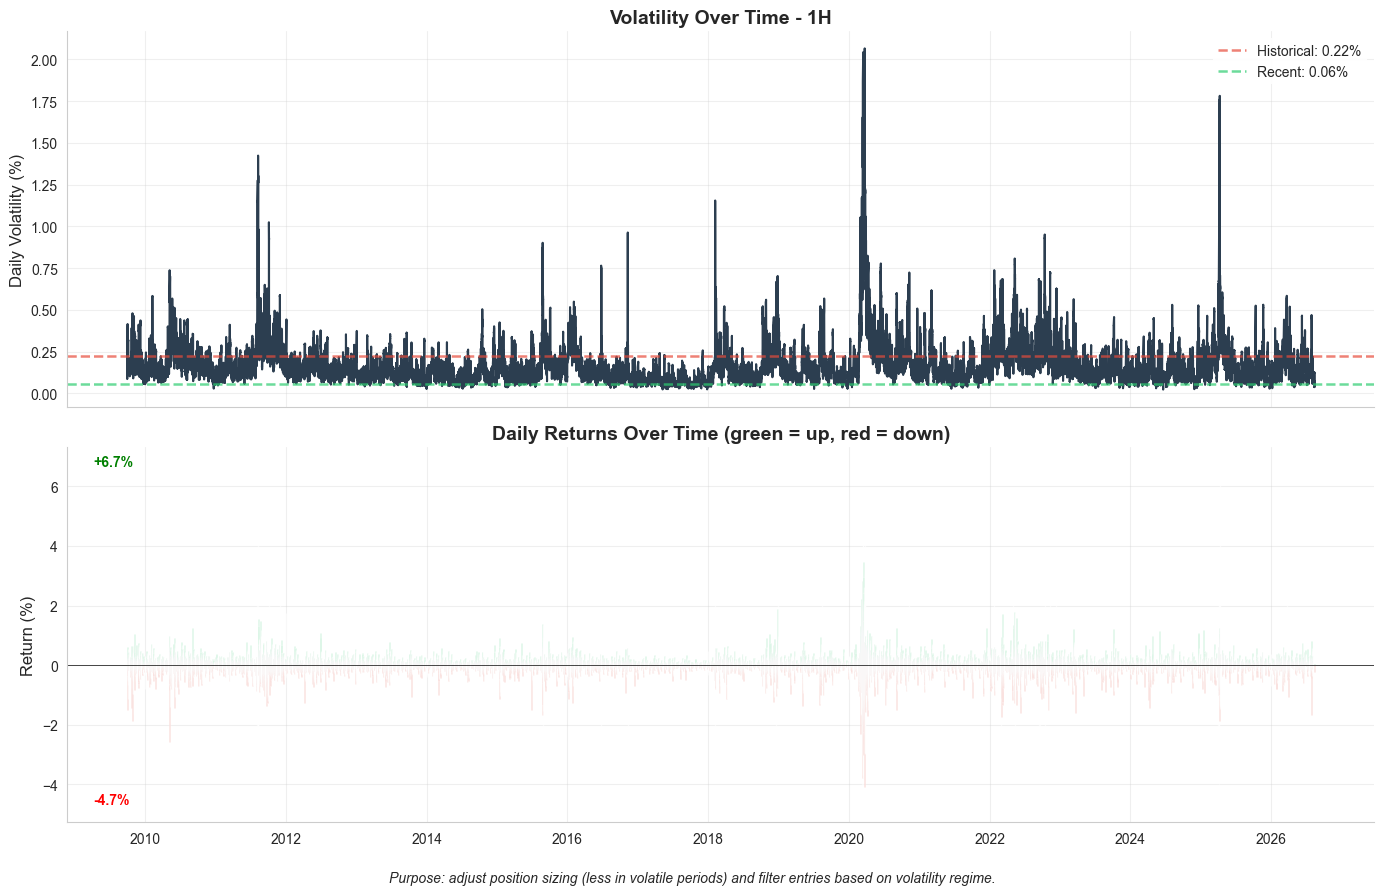


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


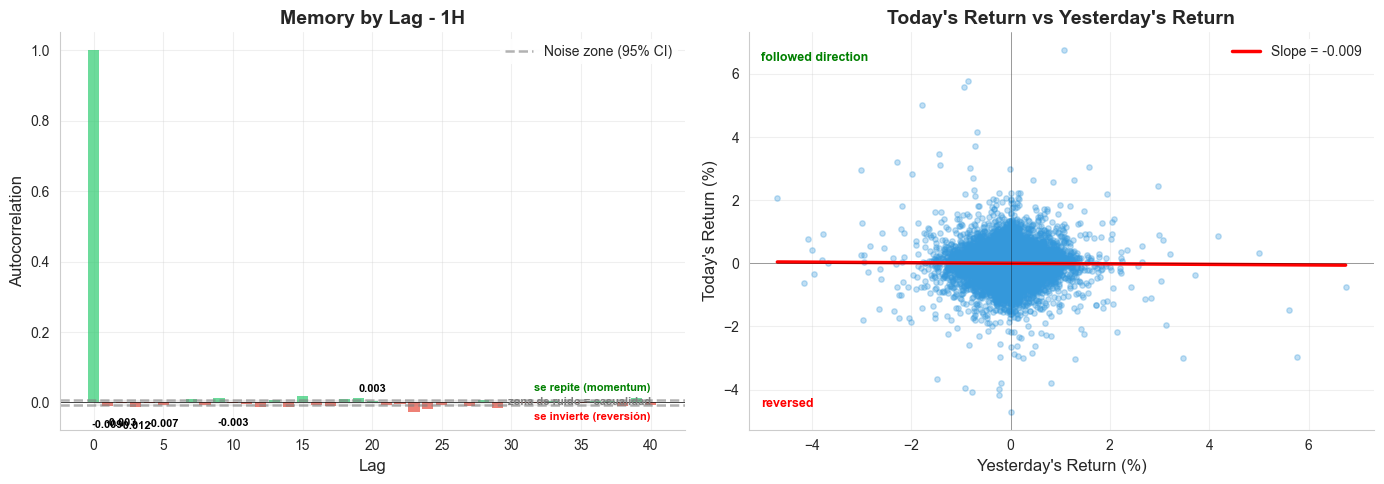


PATTERNS
SEASONALITY?


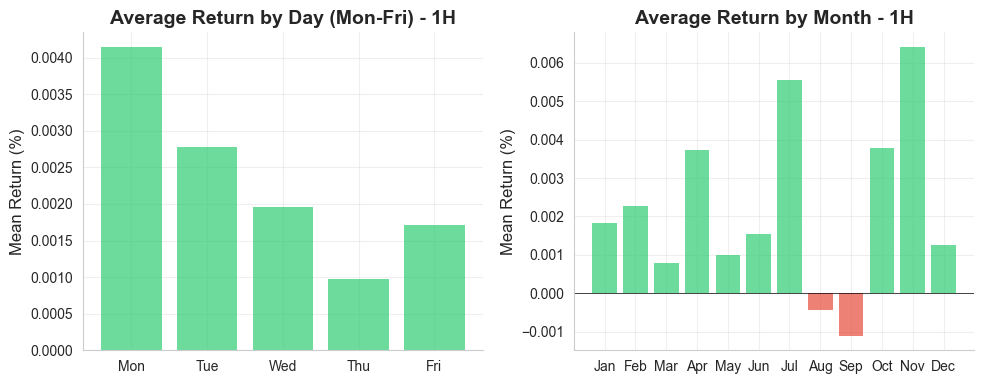


Average return by day of week (Mon-Fri, %):
Mon: 0.00%
Tue: 0.00%
Wed: 0.00%
Thu: 0.00%
Fri: 0.00%

Average return by month (%):
Jan: 0.00%
Feb: 0.00%
Mar: 0.00%
Apr: 0.00%
May: 0.00%
Jun: 0.00%
Jul: 0.01%
Aug: -0.00%
Sep: -0.00%
Oct: 0.00%
Nov: 0.01%
Dec: 0.00%

EXTREME EVENTS
REACTION?


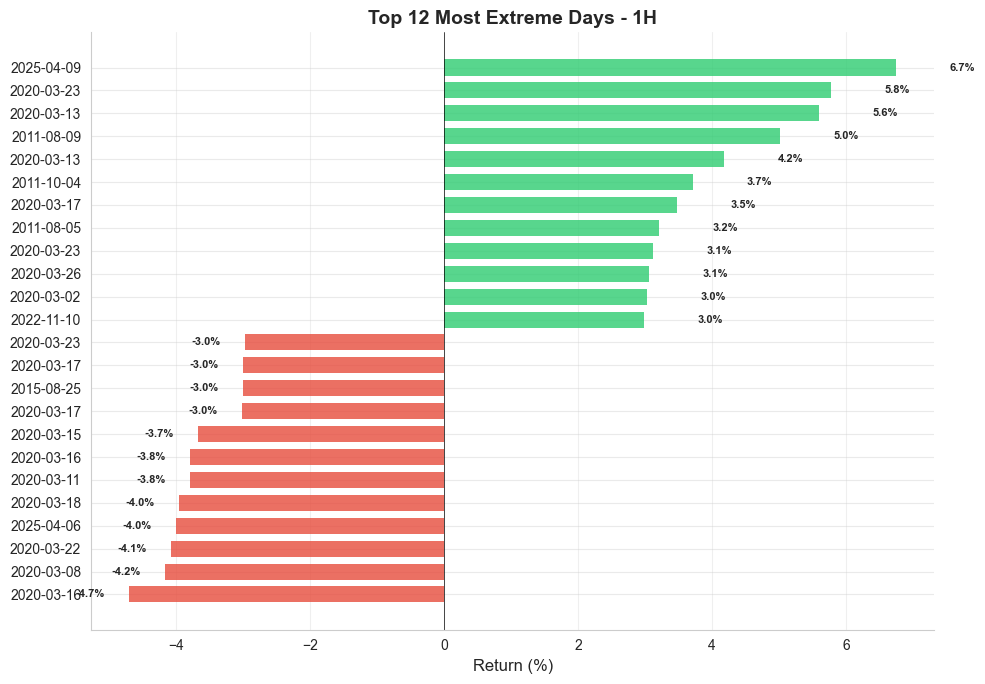

Biggest up: +6.7%
Biggest down: -4.7%
Shock days (>3σ): 1795 of 101,020 returns · 1.78%

Top 12 up days:
+6.7% - 2025-04-09
+5.8% - 2020-03-23
+5.6% - 2020-03-13
+5.0% - 2011-08-09
+4.2% - 2020-03-13
+3.7% - 2011-10-04
+3.5% - 2020-03-17
+3.2% - 2011-08-05
+3.1% - 2020-03-23
+3.1% - 2020-03-26
+3.0% - 2020-03-02
+3.0% - 2022-11-10

Top 12 down days:
-4.7% - 2020-03-16
-4.2% - 2020-03-08
-4.1% - 2020-03-22
-4.0% - 2025-04-06
-4.0% - 2020-03-18
-3.8% - 2020-03-11
-3.8% - 2020-03-16
-3.7% - 2020-03-15
-3.0% - 2020-03-17
-3.0% - 2015-08-25
-3.0% - 2020-03-17
-3.0% - 2020-03-23

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal sys

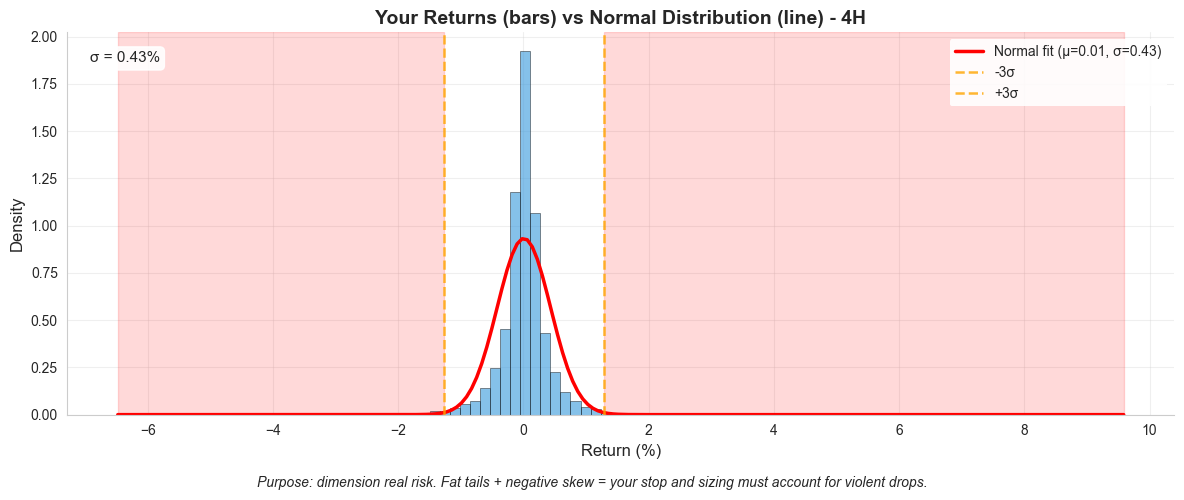


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.31x
Recent volatility (daily): 0.13%
Historical volatility (daily): 0.43%
Comes in waves? low


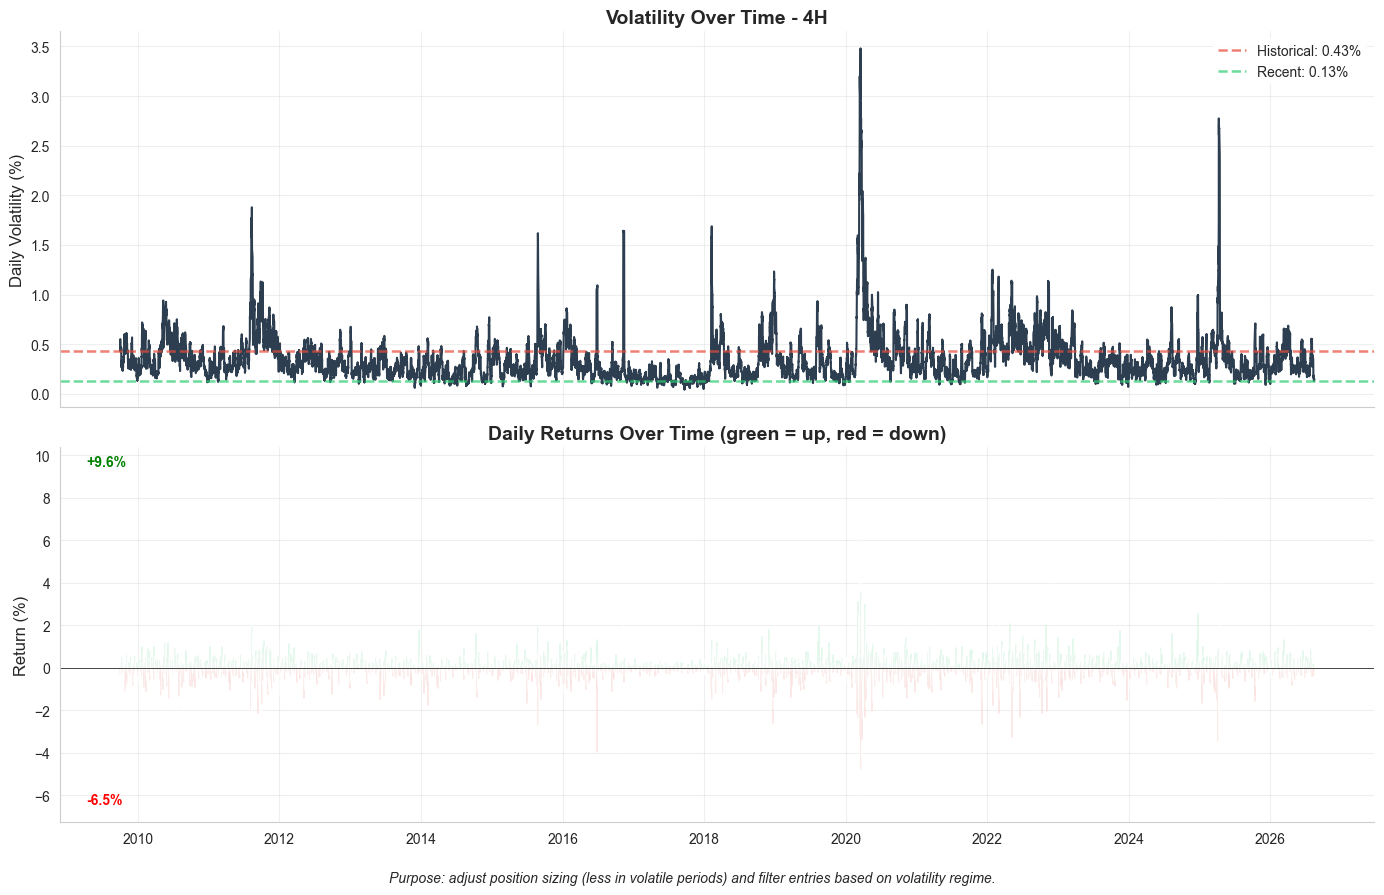


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.01 ~0


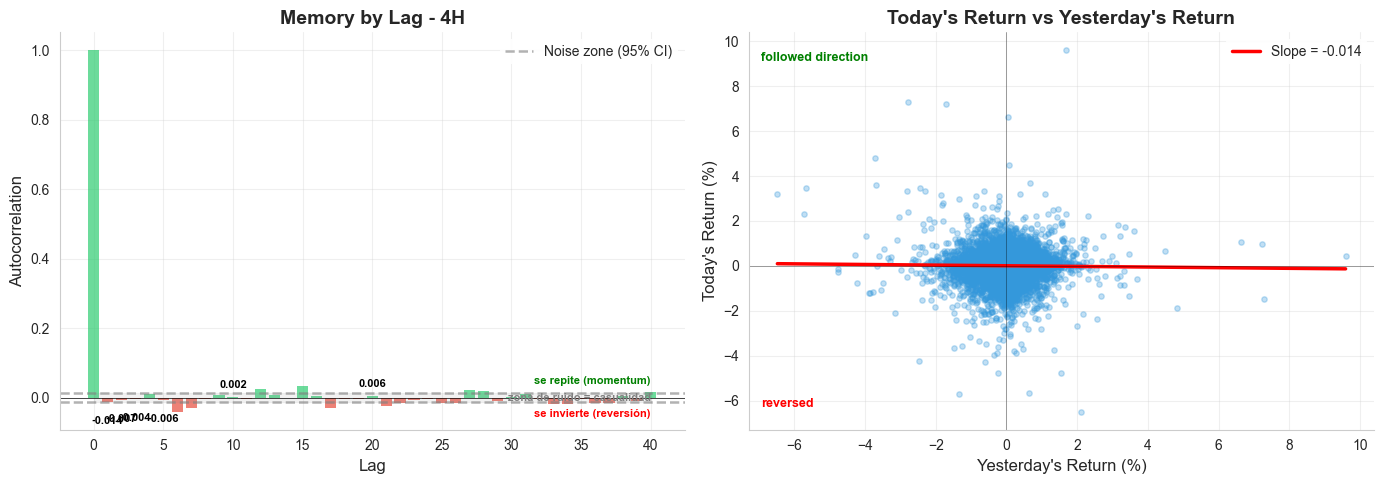


PATTERNS
SEASONALITY?


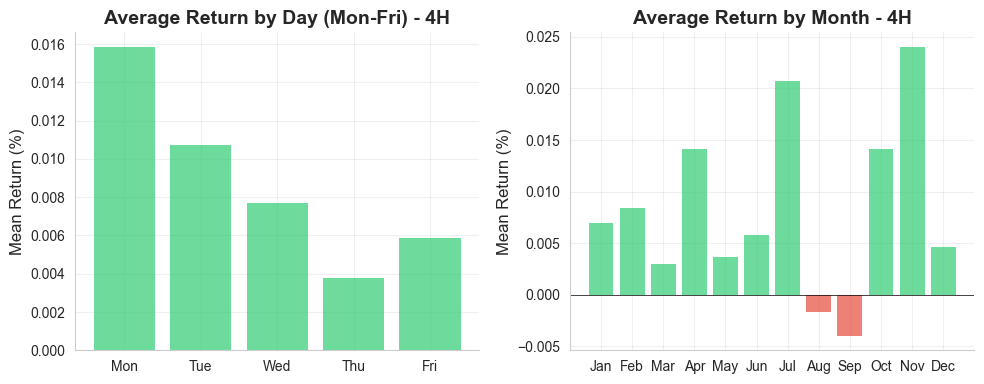


Average return by day of week (Mon-Fri, %):
Mon: 0.02%
Tue: 0.01%
Wed: 0.01%
Thu: 0.00%
Fri: 0.01%

Average return by month (%):
Jan: 0.01%
Feb: 0.01%
Mar: 0.00%
Apr: 0.01%
May: 0.00%
Jun: 0.01%
Jul: 0.02%
Aug: -0.00%
Sep: -0.00%
Oct: 0.01%
Nov: 0.02%
Dec: 0.00%

EXTREME EVENTS
REACTION?


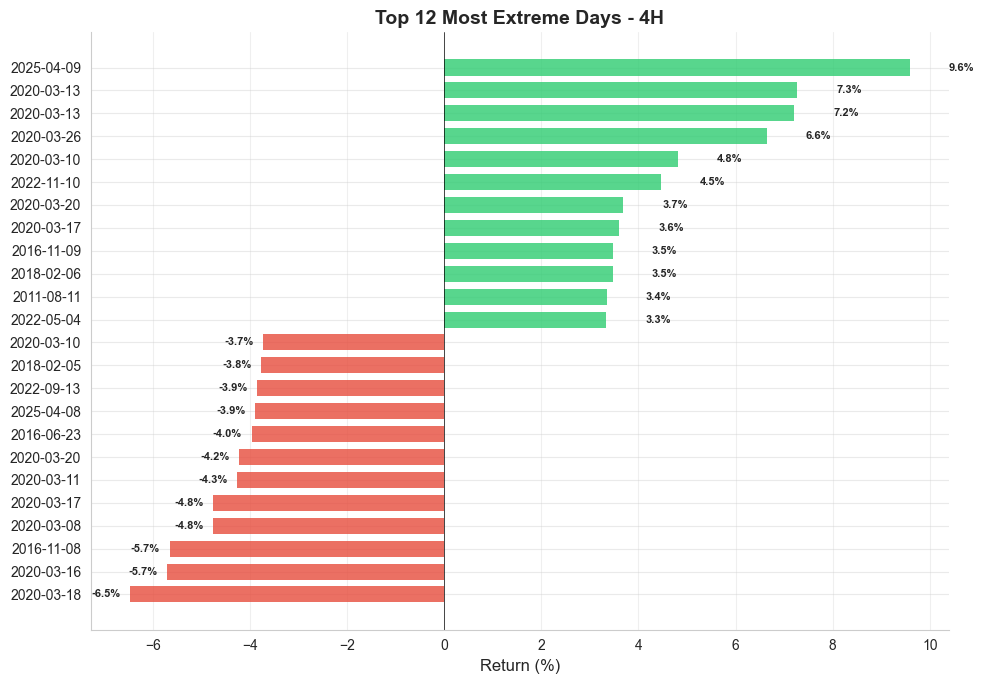

Biggest up: +9.6%
Biggest down: -6.5%
Shock days (>3σ): 471 of 26,969 returns · 1.75%

Top 12 up days:
+9.6% - 2025-04-09
+7.3% - 2020-03-13
+7.2% - 2020-03-13
+6.6% - 2020-03-26
+4.8% - 2020-03-10
+4.5% - 2022-11-10
+3.7% - 2020-03-20
+3.6% - 2020-03-17
+3.5% - 2016-11-09
+3.5% - 2018-02-06
+3.4% - 2011-08-11
+3.3% - 2022-05-04

Top 12 down days:
-6.5% - 2020-03-18
-5.7% - 2020-03-16
-5.7% - 2016-11-08
-4.8% - 2020-03-08
-4.8% - 2020-03-17
-4.3% - 2020-03-11
-4.2% - 2020-03-20
-4.0% - 2016-06-23
-3.9% - 2025-04-08
-3.9% - 2022-09-13
-3.8% - 2018-02-05
-3.7% - 2020-03-10

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	low
Response to 

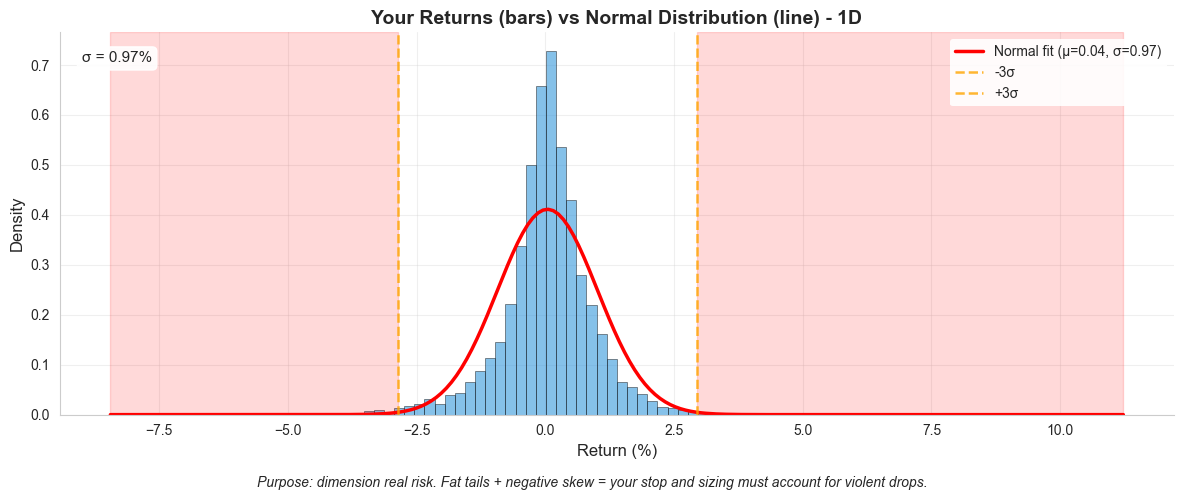


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.66x
Recent volatility (daily): 0.64%
Historical volatility (daily): 0.97%
Comes in waves? strong


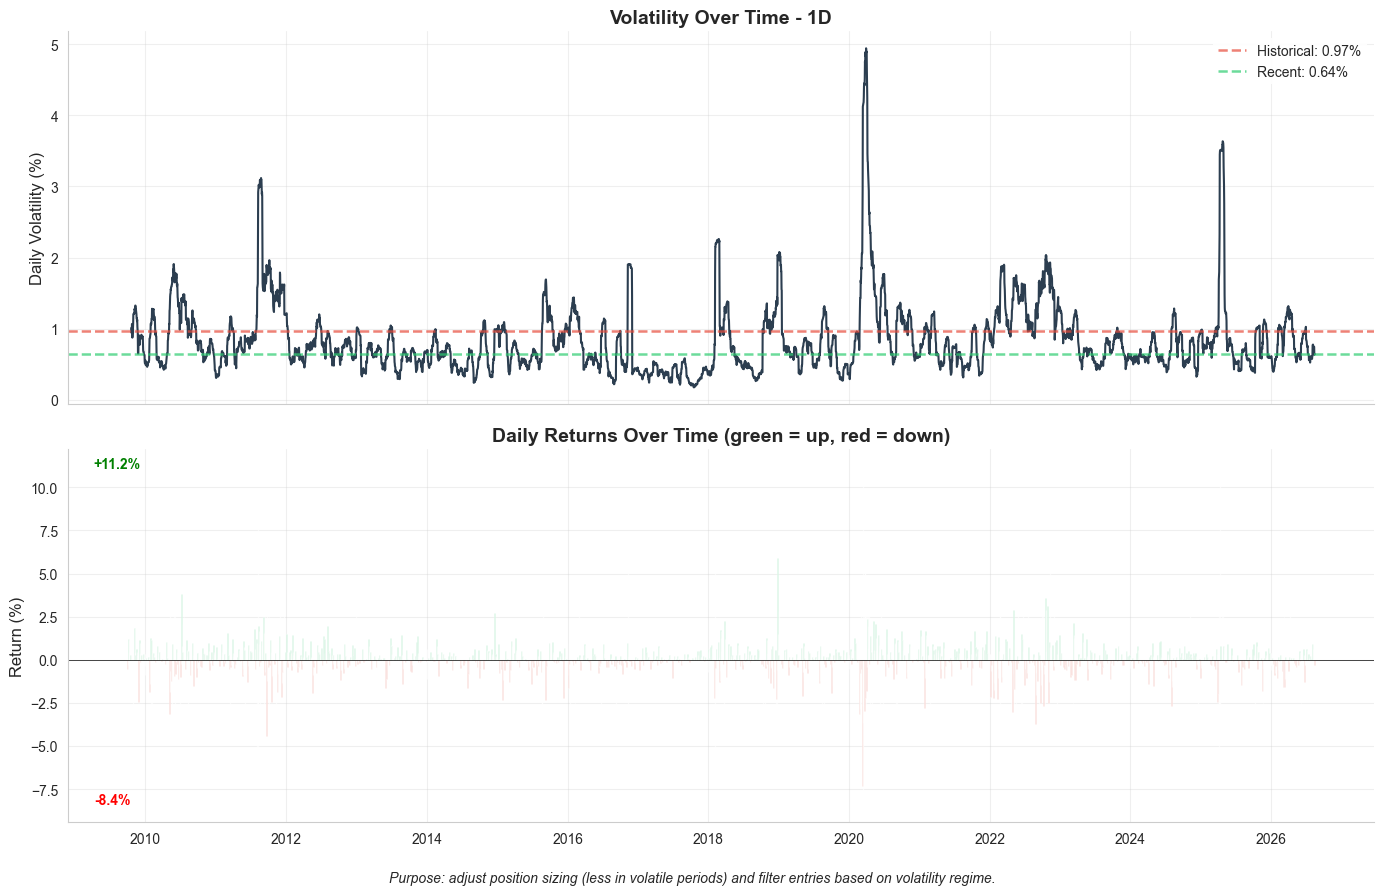


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.07 reverts
Lag 5 · vs 5 days ago: -0.01 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


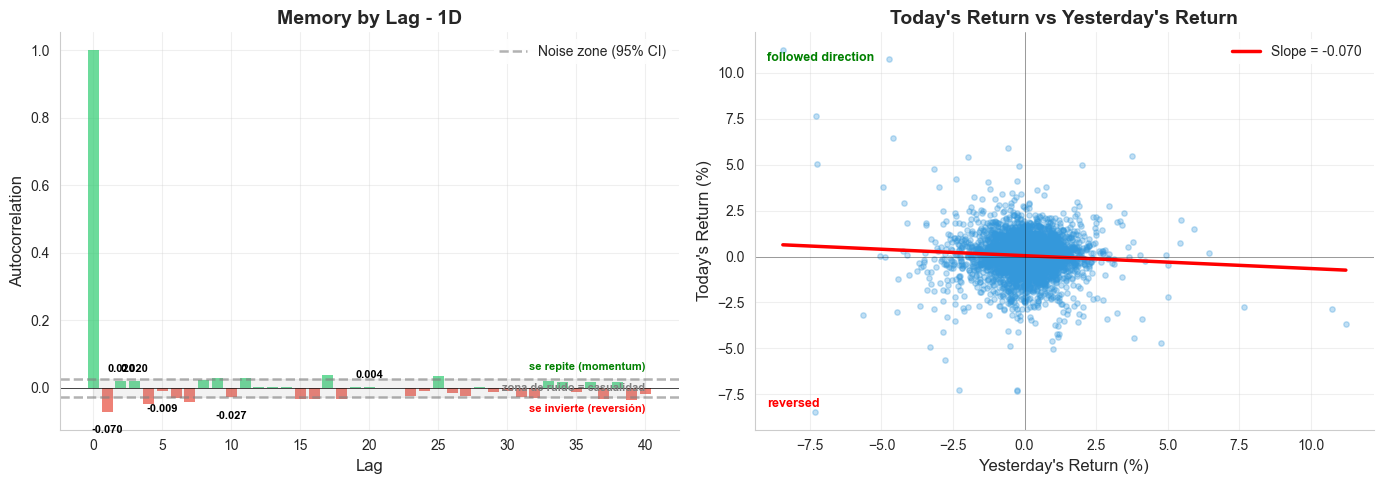


PATTERNS
SEASONALITY?


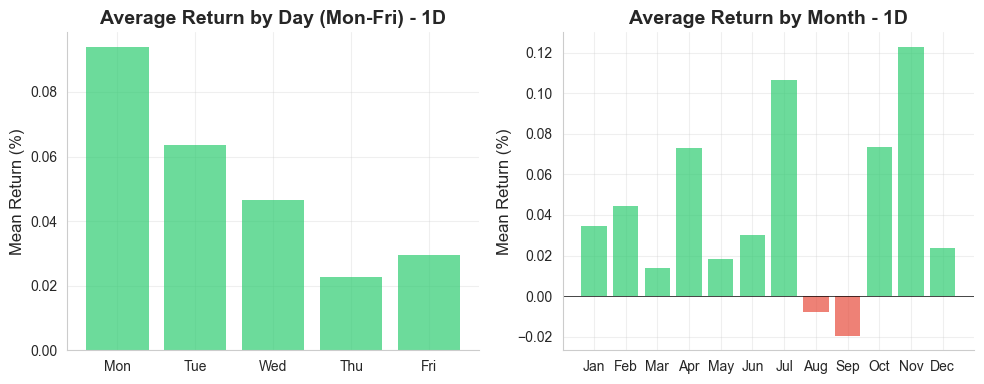


Average return by day of week (Mon-Fri, %):
Mon: 0.09%
Tue: 0.06%
Wed: 0.05%
Thu: 0.02%
Fri: 0.03%

Average return by month (%):
Jan: 0.03%
Feb: 0.04%
Mar: 0.01%
Apr: 0.07%
May: 0.02%
Jun: 0.03%
Jul: 0.11%
Aug: -0.01%
Sep: -0.02%
Oct: 0.07%
Nov: 0.12%
Dec: 0.02%

EXTREME EVENTS
REACTION?


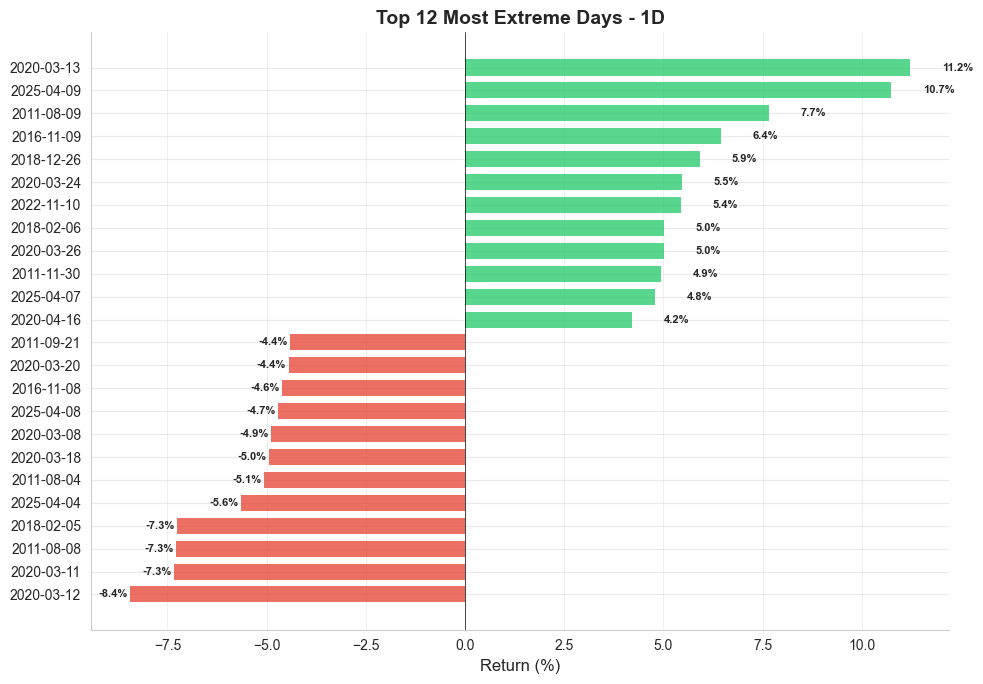

Biggest up: +11.2%
Biggest down: -8.4%
Shock days (>3σ): 76 of 5,251 returns · 1.45%

Top 12 up days:
+11.2% - 2020-03-13
+10.7% - 2025-04-09
+7.7% - 2011-08-09
+6.4% - 2016-11-09
+5.9% - 2018-12-26
+5.5% - 2020-03-24
+5.4% - 2022-11-10
+5.0% - 2018-02-06
+5.0% - 2020-03-26
+4.9% - 2011-11-30
+4.8% - 2025-04-07
+4.2% - 2020-04-16

Top 12 down days:
-8.4% - 2020-03-12
-7.3% - 2020-03-11
-7.3% - 2011-08-08
-7.3% - 2018-02-05
-5.6% - 2025-04-04
-5.1% - 2011-08-04
-5.0% - 2020-03-18
-4.9% - 2020-03-08
-4.7% - 2025-04-08
-4.6% - 2016-11-08
-4.4% - 2020-03-20
-4.4% - 2011-09-21

FROM BEHAVIOR TO SYSTEM
Mean reversion: 57%
Trending: 42%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation negative	→ mean reversion	57%
Volatility regimes	→ volatility expansion	high
Seasonal patterns	→ seasonal systems	high
Response

In [15]:
results = {}
for name, df in [('15min', df_15min), ('1H', df_1h), ('4H', df_4h), ('1D', df_1d)]:
    results[name] = analyze_timeframe_detailed(df, name)

# 8. Summary Comparison Across Timeframes

In [16]:
print("\n" + "="*80)
print("SUMMARY COMPARISON BY TIMEFRAME")
print("="*80)

summary_df = pd.DataFrame({
    'Timeframe': list(results.keys()),
    'Bars': [len(df) for df in [df_15min, df_1h, df_4h, df_1d]],
    'Mean Ret (%)': [r['mean_ret'] for r in results.values()],
    'Vol Ann (%)': [r['vol_ann'] for r in results.values()],
    'Skew': [r['skew'] for r in results.values()],
    'Kurtosis': [r['kurt'] for r in results.values()],
    'Hurst': [r['hurst'] for r in results.values()],
    'MR %': [r['mr_pct'] for r in results.values()],
    'Trend %': [r['trend_pct'] for r in results.values()]
})

print(summary_df.to_string(index=False))

print("\n" + "="*80)
print("FINAL CONCLUSION")
print("="*80)

for name, r in results.items():
    if r['mr_pct'] > 60:
        rec = f"Mean Reversion (MR: {r['mr_pct']:.0f}%) → fade / reversal"
    elif r['trend_pct'] > 60:
        rec = f"Momentum / Breakout (Trend: {r['trend_pct']:.0f}%) → follow trend"
    else:
        rec = f"Mixed (MR: {r['mr_pct']:.0f}%, Trend: {r['trend_pct']:.0f}%) → adaptive or combine both"
    
    print(f"\n{name}: {rec}")
    if r['event'] == 'high':
        print(f"  → High frequency of extreme events ({r['pct_extreme']:.1f}%). Tight stops and conservative sizing.")
    if r['seasonal'] == 'high':
        print(f"  → Seasonality present. Consider seasonal systems.")


SUMMARY COMPARISON BY TIMEFRAME
Timeframe   Bars  Mean Ret (%)  Vol Ann (%)      Skew  Kurtosis    Hurst  MR %  Trend %
    15min 397203      0.000570    15.403398 -0.224584 83.686030 0.499952  50.0     50.0
       1H 101021      0.002236    15.403398  0.108257 49.492660 0.499915  50.0     50.0
       4H  26970      0.008389    15.403398  0.118851 33.767887 0.486430  57.5     42.5
       1D   5252      0.043152    15.403398  0.063176 13.221895 0.470715  57.5     42.5

FINAL CONCLUSION

15min: Mixed (MR: 50%, Trend: 50%) → adaptive or combine both

1H: Mixed (MR: 50%, Trend: 50%) → adaptive or combine both

4H: Mixed (MR: 57%, Trend: 42%) → adaptive or combine both

1D: Mixed (MR: 57%, Trend: 42%) → adaptive or combine both
  → Seasonality present. Consider seasonal systems.
